<!--
Copyright © 2026 The Trustees of Indiana University and contributors.
This work is licensed under the Creative Commons Attribution-NonCommercial 4.0 International License (CC BY-NC 4.0).
You may use, share, and adapt this work for non-commercial purposes, subject to the terms of the license and appropriate attribution.
See the LICENSE file in the root of this repository for the full license terms.
https://creativecommons.org/licenses/by-nc/4.0/
-->

# Exponential Clock Calibration

Samples inter-event deltas from `ExponentialClockManager` across user counts,
visualizes the CCDF(Complementary Cumulative Distribution Function), and fits an exponential rate parameter to see how it scales. 

The $\lambda$ parameter in the exponential distribution is computed based on the number of users in the simulation using a linear regression since there is a linear relationship between the two variables. The parameters of the linear regression were derived emperically from a Bluesky firehose dataset covering 2025-05-01.

This models the distribution of differences (deltas) between each timestamp in a firehose of posts, so each new timestamp can be generated simply by sampling a delta from the distribution, then adding it to the previous timestamp. Like all `ClockManager`s, it also generates IDs that increment by 1.

In [1]:
import sys
sys.path.append("../../../libs/simsom")

from clock_manager import ExponentialClockManager

## Sample Deltas Across User Counts

Generate per-user deltas for each population size to compare distributions.


In [2]:
import numpy as np

user_counts = [1000, 2000, 5000, 10000, 20000, 50000, 100000, 200000, 500000, 1000000, 2000000, 5000000]
all_deltas = []
rng = np.random.default_rng()
for user_count in user_counts:
    clock = ExponentialClockManager(user_count, rng)
    
    deltas = []
    prev_ts = 0
    for _ in range(user_count):
        _, ts = clock.next_time()
        deltas.append(ts - prev_ts)
        prev_ts = ts

    all_deltas.append(deltas)

## Plot CCDFs

Plot simulated CCDFs for each population size on a log scale.


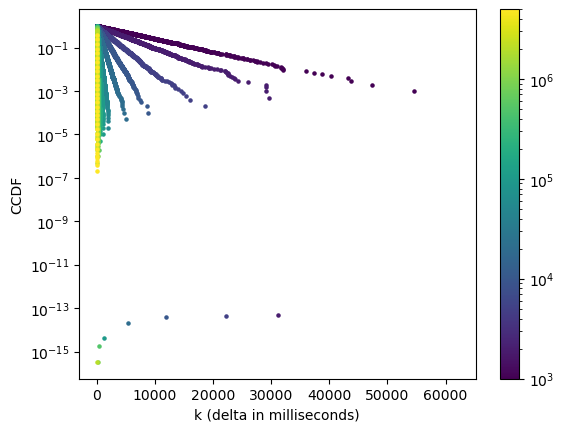

In [3]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from collections import Counter

cmap = cm.viridis
norm = mcolors.LogNorm(vmin=1000, vmax=user_counts[-1])

for deltas, user_count in zip(all_deltas, user_counts):
    counts = Counter(deltas)

    X = np.sort(np.array(list(counts.keys())))

    max_y = sum(counts.values())
    y = [counts[c] / max_y for c in X]

    y = 1 - np.cumsum(y)

    #if user_count ==  max(user_counts):
    plt.scatter(X, y, s=5, color=cmap(norm(user_count)))

scalarmappaple = cm.ScalarMappable(norm=norm, cmap=cmap)
scalarmappaple.set_array(user_counts)
plt.colorbar(scalarmappaple, ax=plt.gca())

plt.xlabel("k (delta in milliseconds)")
plt.ylabel("CCDF")
plt.yscale("log")
plt.show()

## Fit Exponential CCDF

Fit an exponential decay to each CCDF and collect the fitted rate parameter.


In [4]:
from scipy.optimize import curve_fit
from collections import Counter

def exp_ccdf_log(x, lmbda):
    return -lmbda * x

def exp_ccdf(x, lmbda):
    return np.exp(-lmbda * x)

all_lmbda = []
for deltas in all_deltas:
    counts = Counter(deltas)

    X = np.array(list(counts.keys()))

    max_y = sum(counts.values())
    y = np.array([counts[c] / max_y for c in X])

    lmbda, pcov = curve_fit(exp_ccdf_log, X, np.log(y), maxfev=2000)

    all_lmbda.append(lmbda)

## Rate Parameter vs. User Count

Plot how the fitted rate changes with population size.


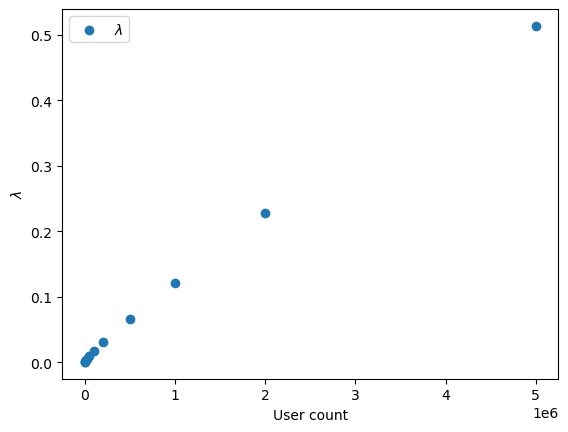

In [5]:
import matplotlib.pyplot as plt

user_counts = np.array(user_counts)

plt.scatter(user_counts, all_lmbda, label=r"$\lambda$")
plt.xlabel("User count")
plt.ylabel(r"$\lambda$")
plt.legend()
plt.show()